# 06 · `to_aseg`, `to_supersynth`, `to_laura`: coarse FreeSurfer-style schemes

These three modules are almost copies of each other. They differ only in:

| | target LUT | mapping YAML | lateralised names | cortex handling | claustrum flag |
|---|---|---|---|---|---|
| `to_aseg` | `FreeSurferColorLUT.txt` | `NextBrainToASeg.yaml` | 15 | keeps DK; left → `ID − 1000` | ✓ |
| `to_supersynth` | `SuperSynthWholeLUT.txt` | `NextBrainToSuperSynth.yaml` | 20 (adds hypothalamus, fornix, MB, basal forebrain, septal) | keeps DK; left → `ID − 1000` | ✓ |
| `to_laura` | `LauraLUT.txt` | `NextBrainToLaura.yaml` | 13 | **all cortex → one label** | ✗ |

The common signature is `to_X(nextbrain, side="L", [claustrum=False], save=False)`.

In [1]:
import sys, os
from pathlib import Path
sys.path.insert(0, ".")          # nb_helpers.py lives next to the notebooks
WORK = Path("_work/06"); WORK.mkdir(parents=True, exist_ok=True)   # scratch outputs of this notebook

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
import nb_helpers as H
pd.set_option("display.max_rows", 60, "display.max_colwidth", 70)

In [2]:
from nextbrain_utils import combine_hemis
from nextbrain_utils import to_aseg as TA, to_supersynth as TS, to_laura as TL
from nextbrain_utils.io import load_lut, load_yaml
nxb_lut = load_lut()
LUTDIR = Path(TA.__file__).parent / "lut"
fs_lut, ss_lut, laura_lut = (load_lut(LUTDIR / f) for f in
                             ["FreeSurferColorLUT.txt", "SuperSynthWholeLUT.txt", "LauraLUT.txt"])

nib.save(H.make_phantom_hemi("L"), WORK / "seg.left.nii.gz")
nib.save(H.make_phantom_hemi("R"), WORK / "seg.right.nii.gz")
combined, sides = combine_hemis(WORK / "seg.left.nii.gz", WORK / "seg.right.nii.gz")
SIDES = str(WORK / "seg.sides.nii.gz")

## How the mapping is built (`get_nextbrain2aseg_map(side, claustrum)`)

1. Start from the identity, `np.arange(max_id + 1)` as `int16`.
2. **Cortex.** For `side="L"`, every ID ≥ 2000 is shifted by −1000, so
   `ctx-rh-X` (20xx) becomes `ctx-lh-X` (10xx). For `side="R"`, nothing
   changes.
3. For each `TargetName: [ids]` entry in the YAML:
   * if `TargetName == "Claustrum"` and `claustrum=False`, use
     `Cerebral-White-Matter` instead;
   * if the name is in the lateralised list, prefix it with `Left-` or `Right-`;
   * look up its ID with `lut.name2label(...)` and write it at every listed
     NextBrain ID.

So the function builds **two** mappings (L and R). With a single string side
it uses one of them. With a sides mask it applies `mapping_left` where
`sides == 1` and `mapping_right` where `sides == 2`. Everything else
(`sides == 0`) becomes 0.

In [3]:
mL, mR = TA.get_nextbrain2aseg_map("L"), TA.get_nextbrain2aseg_map("R")
mLc = TA.get_nextbrain2aseg_map("L", claustrum=True)
for nb_id in [7, 48, 79, 102, 218, 384, 2028]:
    print(f"{nb_id:5d} {nxb_lut.label2name(nb_id):35s} L->{fs_lut.label2name(int(mL[nb_id])):28s}"
          f" R->{fs_lut.label2name(int(mR[nb_id])):28s} L,claustrum->{fs_lut.label2name(int(mLc[nb_id]))}")

    7 white_matter_of_forebrain           L->Left-Cerebral-White-Matter   R->Right-Cerebral-White-Matter  L,claustrum->Left-Cerebral-White-Matter
   48 head_of_caudate                     L->Left-Caudate                 R->Right-Caudate                L,claustrum->Left-Caudate
   79 putamen                             L->Left-Putamen                 R->Right-Putamen                L,claustrum->Left-Putamen
  102 claustrum                           L->Left-Cerebral-White-Matter   R->Right-Cerebral-White-Matter  L,claustrum->Left-Claustrum
  218 thalamus                            L->Left-Thalamus                R->Right-Thalamus               L,claustrum->Left-Thalamus
  384 midbrain_(mesencephalon)            L->Left-VentralDC               R->Right-VentralDC              L,claustrum->Left-VentralDC
 2028 ctx-superiorfrontal                 L->ctx-lh-superiorfrontal       R->ctx-rh-superiorfrontal       L,claustrum->ctx-lh-superiorfrontal


⚠️ **Issue 13**: `claustrum=True` works for ASeg, whose LUT is the full
FreeSurfer table and has `Left/Right-Claustrum` (138/139). It **crashes for
SuperSynth**, whose LUT has no claustrum entry, so `name2label` indexes an
empty selection:

In [4]:
try:
    TS.get_nextbrain2supersynth_map("L", claustrum=True)
except IndexError as e:
    print("IndexError:", e)
print("'Claustrum' in SuperSynth LUT names:", any("Claustrum" in n for n in ss_lut.names))

IndexError: index 0 is out of bounds for axis 0 with size 0
'Claustrum' in SuperSynth LUT names: False


## Applying with the sides mask

⚠️ **Issue 5**: the side mask must be given as a **path**. `_is_side(side)`
calls `side.upper()`, so a nibabel image or an array raises `AttributeError`.

image side -> 'Nifti1Image' object has no attribute 'upper'


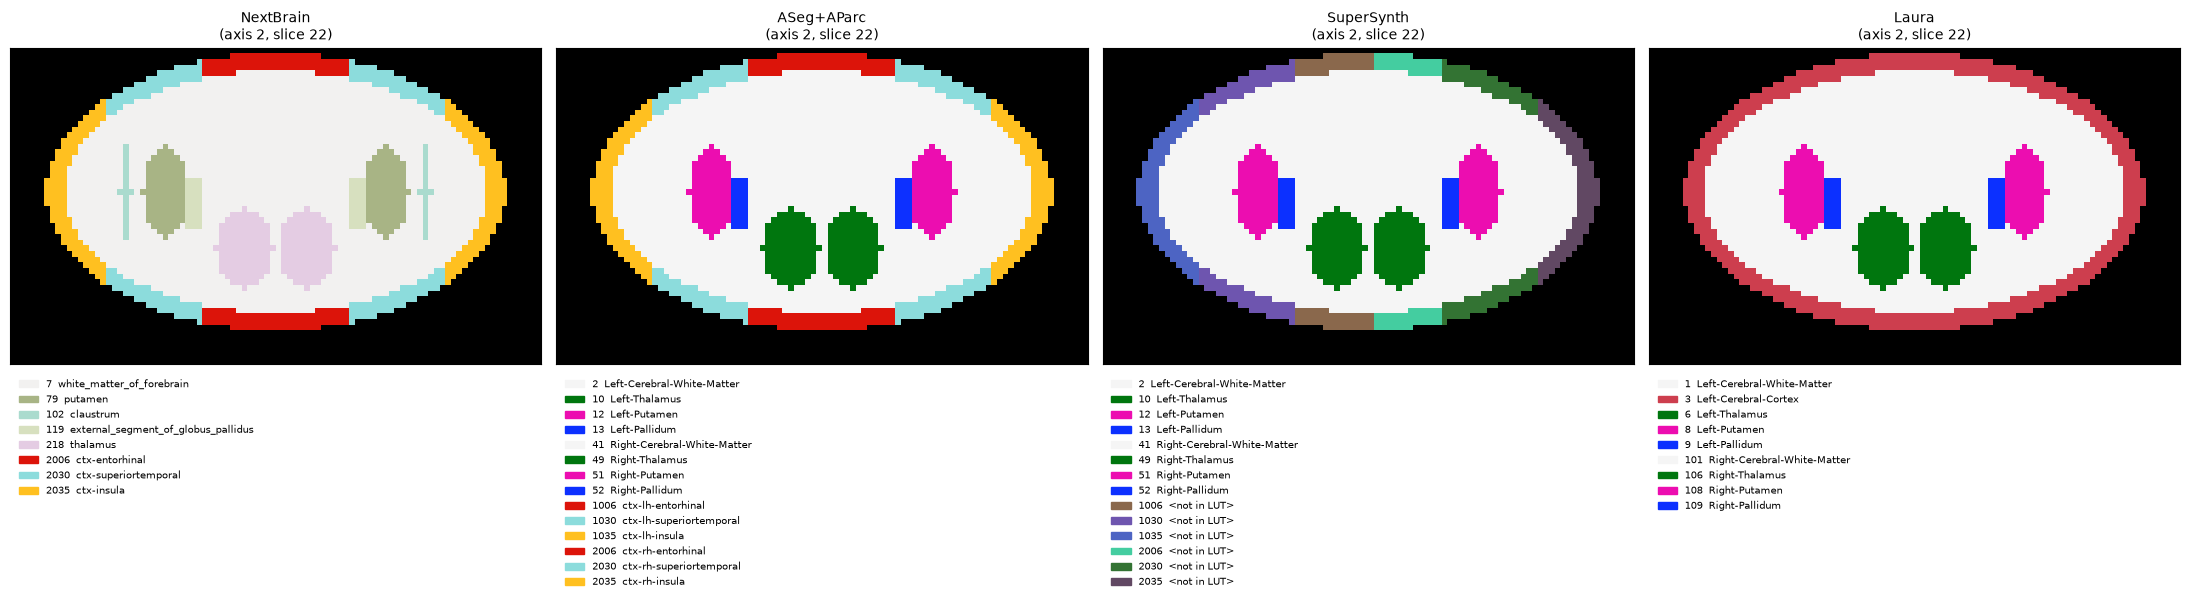

In [5]:
try:
    TA.to_aseg(combined, sides)
except AttributeError as e:
    print("image side ->", e)

aseg = TA.to_aseg(combined, SIDES)
ss   = TS.to_supersynth(combined, SIDES)
lau  = TL.to_laura(combined, SIDES)
H.show_seg([combined, aseg, ss, lau], [nxb_lut, fs_lut, ss_lut, laura_lut], axis=2, index=22,
           titles=["NextBrain", "ASeg+AParc", "SuperSynth", "Laura"], figsize=(22, 7.5))

In [6]:
def per_side(img, lut):
    d, s = np.asarray(img.dataobj), np.asarray(sides.dataobj)
    rows = []
    for side_val, side_name in [(1, "left"), (2, "right")]:
        v, c = np.unique(d[s == side_val], return_counts=True)
        rows += [(side_name, int(a), lut.label2name()[int(a)] if int(a) in lut.label2name() else "<not in LUT>", int(b))
                 for a, b in zip(v, c) if a]
    return pd.DataFrame(rows, columns=["side", "id", "name", "voxels"])
per_side(aseg, fs_lut)

,side,id,name,voxels
0,left,2,Left-Cerebral-White-Matter,28409
1,left,4,Left-Lateral-Ventricle,399
2,left,7,Left-Cerebellum-White-Matter,475
3,left,8,Left-Cerebellum-Cortex,1924
4,left,10,Left-Thalamus,711
5,left,11,Left-Caudate,347
6,left,12,Left-Putamen,771
7,left,13,Left-Pallidum,167
8,left,17,Left-Hippocampus,259
9,left,18,Left-Amygdala,191


## ⚠️ Bug 3: Laura maps all right-hemisphere cortex to the *left* label

```python
nextbrain2laura[nextbrain2laura >= 1000] = 3    # Left-Cerebral-Cortex
nextbrain2laura[nextbrain2laura >= 2000] = 103  # Right-Cerebral-Cortex  <- never true any more
```

After the first line, no entry is ≥ 2000. The cortical labels also do not
depend on `side`, so cortex is `3` in both hemispheres. A fix that respects the
hemisphere would be
`nextbrain2laura[nextbrain2laura >= 1000] = 3 if side == Side.LEFT else 103`.

In [7]:
pl = per_side(lau, laura_lut)
pl[pl.name.str.contains("Cortex|Grey")]

,side,id,name,voxels
1,left,3,Left-Cerebral-Cortex,13272
3,left,5,Left-Cerebellum-Cortex,1924
9,left,11,Left-Hippocampus-Grey-Matter,259
12,right,3,Left-Cerebral-Cortex,12570
17,right,105,Right-Cerebellum-Cortex,1858
22,right,111,Right-Hippocampus-Grey-Matter,259


## SuperSynth: extra lateralised structures

SuperSynth adds hypothalamus (no MB), fornix, mammillary body, basal forebrain
and septal nuclei (the `sclimbic` labels 819–870):

In [8]:
ss_map = load_yaml(LUTDIR / "NextBrainToSuperSynth.yaml")
sR = TS.get_nextbrain2supersynth_map("R")
for k in ["HypoThal-noMB", "Fornix", "MammillaryBody", "Basal-Forebrain", "SeptalNuc"]:
    ids = ss_map.get(k) or []
    if ids:
        print(f"{k:16s} {len(ids):3d} NB labels -> R id {int(sR[ids[0]])} {ss_lut.label2name(int(sR[ids[0]]))}")

HypoThal-noMB     22 NB labels -> R id 820 Right-HypoThal-noMB
Fornix             1 NB labels -> R id 822 Right-Fornix
MammillaryBody     9 NB labels -> R id 844 Right-MammillaryBody
Basal-Forebrain    6 NB labels -> R id 866 Right-Basal-Forebrain
SeptalNuc          1 NB labels -> R id 870 Right-SeptalNuc


## Used labels the YAML forgets pass through unchanged

Any NextBrain ID that the YAML does not list keeps its value. In an ASeg map,
such a value is read as an unrelated FreeSurfer label, or as no label at all.
We restrict the check to the labels NextBrain really outputs
(`NextBrainLabels.yaml`, notebook 01) and show what the stray value *means*
in the target LUT:

In [9]:
used = load_yaml(LUTDIR / "NextBrainLabels.yaml")
used_sub = sorted({i for v in used.values() for i in (v if isinstance(v, list) else [v]) if 0 < i < 1000})
for name, fn, lut in [("aseg", TA.get_nextbrain2aseg_map, fs_lut),
                      ("supersynth", TS.get_nextbrain2supersynth_map, ss_lut),
                      ("laura", TL.get_nextbrain2laura_map, laura_lut)]:
    mp, l2n = fn("R"), lut.label2name()
    passthrough = [i for i in used_sub if mp[i] == i]
    print(f"{name:11s}: {len(passthrough):2d} used labels unchanged, e.g.")
    for i in passthrough[:3]:
        print(f"      {i:4d} {nxb_lut.label2name(i)[:34]:34s} -> read as {l2n.get(i, '<not in LUT>')!r}")

aseg       : 27 used labels unchanged, e.g.
       386 root_of_oculomotor_nerve           -> read as '<not in LUT>'
       401 parabrachial_pigmented_nucleus     -> read as 'V2'
       403 cerebellothalamic_tract            -> read as 'BA45'
supersynth : 29 used labels unchanged, e.g.
        50 anterior_horn_of_lateral_ventricle -> read as 'Right-Caudate'
       114 optic_nerve                        -> read as '<not in LUT>'
       386 root_of_oculomotor_nerve           -> read as '<not in LUT>'
laura      : 72 used labels unchanged, e.g.
        50 anterior_horn_of_lateral_ventricle -> read as '<not in LUT>'
       120 ventral_pallidus                   -> read as '<not in LUT>'
       386 root_of_oculomotor_nerve           -> read as '<not in LUT>'


## Other details

* **Default side.** In Python the default is `"L"`; in the CLI it is `right`.
  The docstrings say the default is "L".
* **Save suffix.** `to_aseg` → `.aseg+aparc`, `to_supersynth` →
  `.supersynth+aparc`, and `to_laura` → also `.aseg+aparc` (issue 9). With
  `save=True` on the same input, Laura and ASeg outputs overwrite each other.
* **No affine for arrays** (issue 4) also applies here.

Next: **07 · The command-line interface and a full pipeline**.